In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)
pth_cb = os.path.join(pth_out, 'colorbars')

In [3]:
# load signatures data from h5ad file
fn = os.path.join(pth_in, 'signatures.h5ad')
adata = sc.read_h5ad(fn); adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'source_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

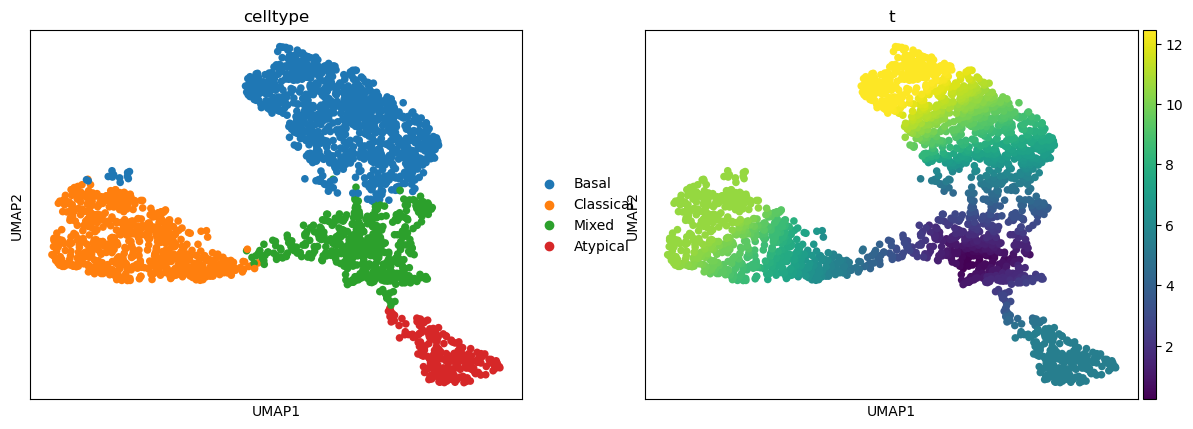

In [4]:
# visual inspection — loaded data
sc.pl.umap(adata, color = ['celltype', 't'], size = 120)

In [5]:
# select module genes — Gast | pSom (XOR)
# these modules display co-repression + cooperation
# during embryonic development
get_feat = lambda pth: set(pd.read_csv(pth).hsapiens)
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.Series(list(gast ^ psom))
g = g.loc[g.isin(adata.var_names)]

In [6]:
# select cell-state convergence
msk = (adata.obs.celltype == 'Mixed')
adata_corr = adata[msk, g].copy()
adata_corr

AnnData object with n_obs × n_vars = 476 × 120
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden', 't', 'seg', 'edge', 'milestones', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'source_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [7]:
# compute pseudotime windows
# adjust n_cells to tune resolution
n_cells, t = 100, adata_corr.obs.t
n_bins = (t.size // n_cells)
t_bin = pd.cut(t, bins = n_bins)
adata_corr.obs['t_bin'] = t_bin
grp = adata_corr.obs.groupby(
    't_bin', observed = True)

In [8]:
# module mutual correlations — windowed
r_dict = dict()
for bin, sdf_bin in grp:
    adata_bin = adata_corr[sdf_bin.index].copy()
    X = pd.DataFrame(adata_bin.X.toarray(),
                     index = sdf_bin.index,
                     columns = g)
    X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
    mod1 = sdf_bin.GSE162534.values[:, None]  # Gast
    mod2 = sdf_bin.GSE229103.values[:, None]  # pSom
    a = pearsonr(X, mod1, axis = 0).statistic
    b = pearsonr(X, mod2, axis = 0).statistic
    r_dict[bin] = np.corrcoef(a, b)[0, 1]

# smooth correlations — neighbors
A = adata_corr.obsp['connectivities']
R = t_bin.map(r_dict).astype(float)
R_sm = (A @ R) / A.sum(axis = 1).A1
adata_corr.obs['correlation'] = R_sm

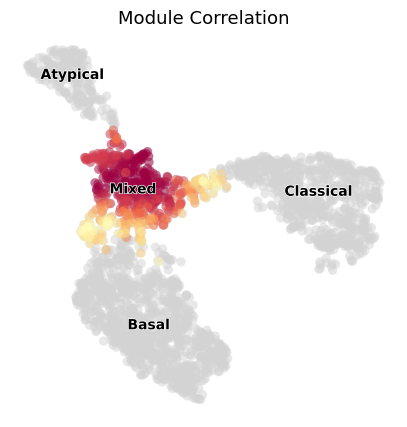

In [9]:
# save module correlation figure
vlim = .5
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 180, alpha = .5,
           frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata_corr, color = 'correlation',
           cmap = 'Spectral', vmin = -vlim,
           vmax = vlim, size = 180, alpha = .5,
           colorbar_loc = None, frameon = False,
           show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 180,
           alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Module Correlation', size = 13)
fn = os.path.join(pth_out, 'correlation.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_1986458/2467224648.py:4: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


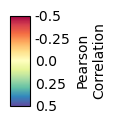

In [10]:
# save module correlation colorbar
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Pearson\nCorrelation')
cb.ax.invert_yaxis()
ticks = np.asarray([-.5, -.25, 0, .25, .5])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fn = os.path.join(pth_cb, 'R_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')